<a href="https://colab.research.google.com/github/Danatelllo/HSE-SOA/blob/master/Hometasks/Base/HW2_Gradient_descent_base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Домашнее задание: Градиентный спуск — базовые концепции**


В этом домашнем задании вы попрактикуетесь в двух вещах:

1. **Градиентный спуск**
   Вы реализуете базовый GD, закрепите на практике его свойства и научитесь интерпретировать результаты.

2. **Дебаггинг**
   По ходу выполнения заданий вам потребуется выявлять и исправлять ошибки — в паре мест — в программной реализации.

##### **Почему дебаггинг?**

На практике, особенно часто при работе с обучением моделей придется читать ошибки и обеспечивать совместимость своего кода с написанным ранее. При этом, написанный ранее код может быть написан не идеально — не важно LLM его писала или человек.

В этом домашнем задании вы:

* реализуете класс GD с треккингом лосса и градиентов;
* проверите, корректно ли ваш оптимизатор работает на разных функциях (в том числе на не выпуклых!);
* потренируетесь читать графики loss;
* получите много красивых визуализаций;

**Ошибки только в функции для графиков!**

**Дедлайн: 13 декабря 23:59**



In [19]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler
import pandas as pd

np.random.seed(42)

### **Функция для картинок**

Эта функция для красивых графиков. Разберитесь в ее работе (можно - при помощи LLM).

<font color="red">В функции в двух местах преднамеренно допущены ошибки. Исправьте их. </font>

In [20]:
def plot_gd_3d(x_range, y_range, Z, loss_fn, history_dict,
               title="Градиентный спуск (3D)", min_point=None):
    """
    3D-график: поверхность + траектории градиентного спуска.

    x_range, y_range : 1D np.array
        Диапазоны по осям x и y.
    Z : 2D np.array
        Значения функции на сетке (len(y_range), len(x_range)).
    loss_fn : callable
        Функция потерь f(params) -> float, чтобы считать z вдоль траекторий.
    history_dict : dict[str, history]
        Словарь: метка -> history, где history['params'] — список параметров.
        Например: {"LR=0.1": gd.history, "LR=0.01": gd2.history}
    min_point : tuple (x*, y*) или None
        Если задано, отмечаем минимум на графике.
    """
    fig = go.Figure()

    # Поверхность функции
    fig.add_trace(
        go.Surface(
            x=x_range,
            y=y_range,
            z=Z,
            opacity=0.7,
            showscale=False
        )
    )

    # Траектории
    # считаются по лоссу
    for label, history in history_dict.items():
        trajectory = np.array(history["params"])  # shape: (T, 2)
        x_traj = trajectory[:, 0]
        y_traj = trajectory[:, 1]
        z_traj = np.array([loss_fn(p) for p in trajectory])  # вот тут

        fig.add_trace(
            go.Scatter3d(
                x=x_traj,
                y=y_traj,
                z=z_traj,
                mode='lines+markers',
                name=label,
                marker=dict(size=4),
                line=dict(width=4)
            )
        )

    # Минимум, если задан
    if min_point is not None:
        x_min, y_min = min_point
        fig.add_trace(
            go.Scatter3d(
                x=[x_min],
                y=[y_min],
                z=[loss_fn(np.array([x_min, y_min]))],
                mode='markers',
                name='Минимум',
                marker=dict(size=6, symbol='diamond-open')
            )
        )

    fig.update_layout(
        title=title,
        scene=dict(
            xaxis_title="x",
            yaxis_title="y",
            zaxis_title="f(x, y)"
        ),
        height=700
    )

    fig.show()


def plot_gd_2d(x_range, y_range, Z, history_dict,
               title="Градиентный спуск (2D контуры)",
               start_points=None, min_point=None,
               contour_kwargs=None):
    """
    2D-контуры + траектории градиентного спуска.

    x_range, y_range : 1D np.array
    Z : 2D np.array
    history_dict : dict[str, history]
        метка -> history, где history['params'] — список параметров.
    start_points : list[np.array] или None
        Список стартовых точек (x0, y0), чтобы нарисовать их на графике.
    min_point : tuple (x*, y*) или None
        Если задано, отмечаем минимум.
    contour_kwargs : dict или None
        Доп. параметры для go.Contour (contours=..., opacity=..., ...).
    """
    if contour_kwargs is None:
        contour_kwargs = dict(
            colorscale='Viridis',
            showscale=False,
            contours=dict(start=0, end=30, size=2),
            opacity=0.7
        )

    fig = go.Figure()

    # Контурный график функции
    fig.add_trace(
        go.Contour(
            x=x_range,
            y=y_range,
            z=Z,
            **contour_kwargs
        )
    )

    # Траектории
    for label, history in history_dict.items():
        trajectory = np.array(history["params"])
        fig.add_trace(
            go.Scatter(
                x=trajectory[:, 0],
                y=trajectory[:, 1],
                mode='lines+markers',
                name=label,
                marker=dict(size=5),
                line=dict(width=3)
            )
        )

    # Стартовые точки (если переданы отдельно)
    if start_points is not None:
        for i, p0 in enumerate(start_points):
            fig.add_trace(
                go.Scatter(
                    x=[p0[0]],
                    y=[p0[1]],  # вот тут
                    mode='markers',
                    name=f'Start {i+1}',
                    marker=dict(size=10, symbol='x')
                )
            )

    # Минимум
    if min_point is not None:
        x_min, y_min = min_point
        fig.add_trace(
            go.Scatter(
                x=[x_min],
                y=[y_min],
                mode='markers',
                name='Минимум',
                marker=dict(size=10, symbol='diamond-open')
            )
        )

    fig.update_layout(
        title=title,
        xaxis_title="x",
        yaxis_title="y",
        height=700
    )

    fig.show()


### **Задание 1. Градиентный спуск: постановка задачи (3 балла)**


Напомним, что в задачах машинного обучения мы хотим минимизировать **функцию потерь**
$$L(w): \mathbb{R}^d \to \mathbb{R},$$
где $w \in \mathbb{R}^d$ — вектор параметров модели (веса), а $L$ измеряет качество этой модели на данных. Пострейший пример функции потерь — MSE потери. Если мы обозначим за $y_i$ истинный прогноз, а за $\hat{y}$ — предсказанный моделью, то MSE — функция вида:

$$L(\hat{y}, y) = \frac{1}{n}\sum_{i=1}^{n} (y - \hat{y})^2$$

Если функция потерь дифференцируема, один из базовых численных методов для её минимизации — **градиентный спуск** (Gradient Descent). Если же функция потерь дифференцируема не везде — мы используем в "плохих точках" [субградиент](https://www.google.com/search?client=safari&rls=en&q=%D0%A1%D1%83%D0%B1%D0%B3%D1%80%D0%B0%D0%B4%D0%B8%D0%B5%D0%BD%D1%82&ie=UTF-8&oe=UTF-8).

#### **Идея метода градиетного спуска**

Градиент $\nabla L(w)$ по определению показывает направление **наискорейшего роста** функции. Чтобы уменьшать значение $L(w)$, нужно двигаться в противоположную сторону — туда, где функция убывает:

$$w_{k+1} = w_k - \eta \nabla L(w_k),$$

где

* $w_k$ — параметры на итерации $k$,
* $\eta > 0$ — шаг обучения (learning rate),
* $\nabla L(w_k)$ — градиент функции потерь по параметрам $w$ в точке $w_k$.

При достаточно «хороших» свойствах $L(w)$ (выпуклость — можно обозвать это "парабольным" поведением и гладкость — дифференцируемость везде) и правильно подобранном шаге $\eta$ последовательность ${w_k}$ будет стремиться к точке минимума. На практике, свойства функции мы проверяем не всегда, так как используем золотой набор функций устоявшийся в области и ключевую роль играет шаг $\eta$.

#### **Детали? Детали!**

При реализации градиентного спуска нужно учитывать:

1. **Инициализацию**

   Необходимо задать начальное значение параметров $w_0$.

2. **Шаг обучения $\eta$**

     Его правильный подбор — это искусство.

3. **Критерии остановки**

   Обычно метод выполняется фиксированное число итераций $N$, либо пока не выполнится одно из условий:

   * $|\nabla L(w_k)|$ стало достаточно малым;
   * изменение параметров $|w_{k+1} - w_k|$ мало;
   * изменение значения потерь $|L(w_{k+1}) - L(w_k)|$ мало.

4. **История обучения**

   Для анализа работы алгоритма полезно сохранять:

   * значения параметров $w_k$ на каждой итерации;
   * значения функции потерь $L(w_k)$;
   * (не обязательно, но полезно) значения нормы градиента $|\nabla L(w_k)|$.

    Эта информация позволит визуализировать траекторию спуска и поведение loss-функции во времени. Когда у нас есть этот график (да и вообще все 3 из перечисленных), мы можем понимать, как у обучения дела.


#### **1. Выпуклость и нет (1.5 балла)**

Из теории мы также знаем, что хочется минимизировать **выпуклые функции**. Почему именно их? Они приятные и у них:

* либо один глобальный минимум,
* либо целое выпуклое множество глобальных минимумов,
* нет локальных минимумов.

Это означает, что при разумном шаге градиентный спуск, стартуя из любой точки, будет стремиться к глобальному минимуму.

Формально, функция $f:\mathbb{R}^d \to \mathbb{R}$ называется **выпуклой**, если для любых $x, y \in \mathbb{R}^d$ и $\lambda \in [0, 1]$:
$$f(\lambda x + (1-\lambda) y) \leq \lambda f(x) + (1-\lambda) f(y)$$

Для дважды дифференцируемых функций это эквивалентно тому, что их **матрица Гессе** (матрица вторых производных) неотрицательно определена во всех точках.

Но это всё детали. Которые полезно знать. Но в реальных задачах машинного обучения мы почти всегда сталкиваемся с **невыпуклыми** функциями потерь.

Уметь понимать поведение на выпуклом и невыпуклом ландшафте по лоссу/градиенту важно, потому что это поможет вам в будущем изучать графики ваших моделей более четко и понимать, почему обучение застряло и что с этим можно сделать (добавить инерцию, перестартануть с других точек и так далее). Что же, давайте знакомиться с разным поведением!

#### **1. 1. Задание: реализуйте в коде функции и их градиенты**

1. **Простая квадратичная функция** (выпуклая):
   
   $f(x, y) = x^2 + y^2.$

2. **Функция Розенброка ([Rosenbrock's banana function](https://ru.wikipedia.org/wiki/%D0%A4%D1%83%D0%BD%D0%BA%D1%86%D0%B8%D1%8F_%D0%A0%D0%BE%D0%B7%D0%B5%D0%BD%D0%B1%D1%80%D0%BE%D0%BA%D0%B0))**:

   $f_{\text{R}}(x, y) = (a - x)^2 + b(y - x^2)^2$, тут по умолчанию a=1, b=100, но далее надо реализовывать a и b как гиперпараметры.

Мы будем использовать эти функции дальше для визуализации траекторий градиентного спуска, сравнения влияния шага обучения и анализа ландшафта.

**Ваши задачи в этом подпункте:**

1. Реализовать функции:

   * `quadratic_loss(params)`
   * `rosenbrock_loss(params, a=1, b=100)`

2. Реализовать их градиенты:

   * `quadratic_grad(params)` — возвращает `[grad_x, grad_y]`
   * `rosenbrock_grad(params, a=1, b=100)` — возвращает `[grad_x, grad_y]`


Дальше эти функции будут использоваться в классе `GradientDescent` для экспериментов с разными значениями шага обучения и для 2D/3D визуализаций ландшафта.



In [21]:
# Квадратичная функция
def quadratic_loss(params):
    """
    params: list — список, вида [x, y]
    f(x, y) = x^2 + y^2
    """
    x, y = params
    return x**2 + y**2

def quadratic_grad(params):
    """
    Градиент квадратичной функции.
    ∂f/∂x = 2x
    ∂f/∂y = 2y
    """
    x, y = params
    return np.array([2*x, 2*y])

# Функция Розенброка
def rosenbrock_loss(params, a=1, b=100):
    """
    params: list — список, вида [x, y]
    f(x, y) = (a - x)^2 + b(y - x^2)^2
    """
    x, y = params
    return (a - x)**2 + b * (y - x**2)**2

def rosenbrock_grad(params, a=1, b=100):
    """
    Градиент функции Розенброка.

    f(x, y) = (a - x)^2 + b(y - x^2)^2

    ∂f/∂x = 2(a - x)·(-1) + b·2(y - x^2)·(-2x)
          = -2(a - x) - 4bx(y - x^2)

    ∂f/∂y = b·2(y - x^2)·1
          = 2b(y - x^2)
    """
    x, y = params
    df_dx = -2*(a - x) - 4*b*x*(y - x**2)
    df_dy = 2*b*(y - x**2)
    return np.array([df_dx, df_dy])



#### **1. 2. Реализуйте классический (ванильный) градиентный спуск (1.5 балла)**

Теперь давайте сделаем **класс градиентного спуска** `GradientDescent`, в котором будет помимо прочего реализовано подробное логирование. Все параметры, которые класс принимает на вход, описаны ниже и соответствуют теоретической постановке задачи.

In [22]:
class GradientDescent:
    """
    Класс для базовой реализации градиентного спуска

    Parameters
    ----------
    learning_rate : float
        Скорость спуска (шаг обучения η)
    n_iterations : int
        Максимальное количество итераций спуска

    Attributes
    ----------
    history : dict
        Словарь, который хранит историю обучения:
        - 'params': список параметров на каждой итерации
        - 'loss': список значений функции потерь
        - 'gradients': список градиентов
    """

    def __init__(self, learning_rate=0.01, n_iterations=100):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.history = {
            'params': [],
            'loss': [],
            'gradients': []
        }

    def fit(self, loss_fn, grad_fn, initial_params):
        """
        Обучение с помощью градиентного спуска

        Parameters
        ----------
        loss_fn : callable
            Функция потерь L(params) -> float
        grad_fn : callable
            Функция градиента ∇L(params) -> np.array
        initial_params : np.array or list
            Начальные параметры

        Returns
        -------
        params : np.array
            Финальные параметры после оптимизации
        """
        params = np.array(initial_params).copy()

        for i in range(self.n_iterations):
            grad = grad_fn(params)
            self.history['params'].append(params.copy())
            self.history['loss'].append(loss_fn(params))
            self.history['gradients'].append(grad.copy())

            params = params - self.learning_rate * grad

        self.history['params'].append(params.copy())
        self.history['loss'].append(loss_fn(params))
        self.history['gradients'].append(grad_fn(params))

        return params


Теперь проверим работоспособность функций, но если вы сделали это выше при реализации — вам только плюсы!

Мы будем использовать библиотеку plotly, чтобы получить функциональные графики — которые можно приближать, отдалять, крутить и так далее. Нарисуем полученные функции в 3D и протестируем градиентный спуск. Вернее, его параметры.

### **Задание 2. Анализ гиперпараметров градиетного спуска (2 балла)**


Learning rate (в разных нотациях его обозначают за $\eta или \alpha$) — основной гиперпараметр градиетного спуска и любой его модификации. Даже для простой выпуклой функции (например, квадратичной) заведомо неверный выбор шага делает обучение неэффективным или просто расходящимся.

Давайте проанализруем влияние шага обучения на поведение градиентного спуска.
Для этого:

1. Возьмите несколько значений learning rate:
   $$\eta \in \{0.001,\ 0.01,\ 0.1,\ 0.5,\ 1.0\}.$$

2. Возьмите несколько стартовых точек.
   
3. Протестируйте работу реализованного класса работу на двух функциях:

   * выпуклой функции
     $$f(x, y) = x^2 + y^2,$$
   * невыпуклой функции Розенброка
     $$f(x, y) = (1 - x)^2 + 100 (y - x^2)^2$$
4. Сделайте выводы.


In [23]:
learning_rates = [0.001, 0.1, 0.5, 0.9]
initial_point = np.array([1.0, 1.0])

x_range = np.linspace(-2, 2, 100)
y_range = np.linspace(-2, 2, 100)
X, Y = np.meshgrid(x_range, y_range)
Z = X**2 + Y**2

results_lr_quadr = {}


for lr in learning_rates:
    gd = GradientDescent(learning_rate=lr, n_iterations=100)

    final_params = gd.fit(quadratic_loss, quadratic_grad, initial_point)

    results_lr_quadr[lr] = gd.history

    print(f"LR = {lr}: Final loss = {quadratic_loss(final_params):.6f}, "
          f"Final params = [{final_params[0]:.4f}, {final_params[1]:.4f}]")


LR = 0.001: Final loss = 1.340103, Final params = [0.8186, 0.8186]
LR = 0.1: Final loss = 0.000000, Final params = [0.0000, 0.0000]
LR = 0.5: Final loss = 0.000000, Final params = [0.0000, 0.0000]
LR = 0.9: Final loss = 0.000000, Final params = [0.0000, 0.0000]


In [24]:
plot_gd_3d(
    x_range=x_range,
    y_range=y_range,
    Z=Z,
    loss_fn=quadratic_loss,
    history_dict=results_lr_quadr,
    title="Квадратичная функция: траектории GD (3D)",
    min_point=(0.0, 0.0)
)

plot_gd_2d(
    x_range=x_range,
    y_range=y_range,
    Z=Z,
    history_dict=results_lr_quadr,
    title="Квадратичная функция: траектории GD (2D контуры)",
    start_points=[initial_point],
    min_point=(0.0, 0.0),
    contour_kwargs=dict(
        colorscale='Viridis',
        showscale=False,
        contours=dict(start=0, end=30, size=2),
        opacity=0.7
    )
)


In [25]:


x_range = np.linspace(-2, 2, 200)
y_range = np.linspace(-1, 3, 200)
X, Y = np.meshgrid(x_range, y_range)
Z = (1 - X)**2 + 100 * (Y - X**2)**2

initial_point = np.array([-0.5, 0.5])

results_lr_banna = {}

print(f"Начальная точка: {initial_point}")
print(f"Начальный loss: {rosenbrock_loss(initial_point):.6f}")
print("-" * 70)


for lr in learning_rates:
    gd = GradientDescent(learning_rate=lr, n_iterations=10000)
    final_rosen = gd.fit(rosenbrock_loss, rosenbrock_grad, initial_point)
    results_lr_banna[lr] = gd.history

    print(f"LR = {lr}: Final Rosenbrock loss = {rosenbrock_loss(final_rosen):.6f}, "
          f"Final params = [{final_rosen[0]:.4f}, {final_rosen[1]:.4f}]")


Начальная точка: [-0.5  0.5]
Начальный loss: 8.500000
----------------------------------------------------------------------
LR = 0.001: Final Rosenbrock loss = 0.000042, Final params = [0.9936, 0.9871]
LR = 0.1: Final Rosenbrock loss = nan, Final params = [nan, nan]


/tmp/ipython-input-313313402.py:41: RuntimeWarning:

overflow encountered in scalar multiply

/tmp/ipython-input-313313402.py:26: RuntimeWarning:

overflow encountered in scalar power

/tmp/ipython-input-991666534.py:56: RuntimeWarning:

invalid value encountered in subtract

/tmp/ipython-input-313313402.py:41: RuntimeWarning:

overflow encountered in scalar power

/tmp/ipython-input-313313402.py:42: RuntimeWarning:

overflow encountered in scalar power

/tmp/ipython-input-313313402.py:41: RuntimeWarning:

invalid value encountered in scalar subtract

/tmp/ipython-input-313313402.py:42: RuntimeWarning:

invalid value encountered in scalar subtract

/tmp/ipython-input-313313402.py:26: RuntimeWarning:

invalid value encountered in scalar subtract



LR = 0.5: Final Rosenbrock loss = nan, Final params = [nan, nan]
LR = 0.9: Final Rosenbrock loss = nan, Final params = [nan, nan]


In [26]:
plot_gd_3d(
    x_range=x_range,
    y_range=y_range,
    Z=Z,
    loss_fn=rosenbrock_loss,
    history_dict=results_lr_quadr,
    title="Rosenbrock функция: траектории GD (3D)",
    min_point=(0.0, 0.0)
)

plot_gd_2d(
    x_range=x_range,
    y_range=y_range,
    Z=Z,
    history_dict=results_lr_quadr,
    title="Rosenbrock функция: траектории GD (2D контуры)",
    start_points=[initial_point],
    min_point=(0.0, 0.0),
    contour_kwargs=dict(
        colorscale='Viridis',
        showscale=False,
        contours=dict(start=0, end=30, size=2),
        opacity=0.7
    )
)


**Ваши выводы здесь**
Квадратичная фукнция потерь: самый маленький learning rate видно, что не успели сойтись, 0,1-05 идут вдоль функции потерь, 0.9 пример на грани learning rate - бьемся об стенки слишком большой шаг

Видно, что большие learning rates (0.1, 0.5) вызывают переполнение и расходимость для функции Розенброка. Нужно использовать гораздо меньшие значения.

### **Задание 3. Анализ Losses (2 балла)**

Реализованный вами класс также сохранял графики loss-функции. Их в процессе обучения мы также анализируем. Говорят, что **loss “сходится”**, если выполняются следующие признаки:

1. Значение loss $L(w_k)$ монотонно убывает и приближается к некоторому предельному значению (выходит на плато):
   $$|L(w_{k+1}) - L(w_k)| \to 0$$

Сошелся ли лосс у нас? Для ответы используйте реализованные вами методы из заданий 1–2:

1. **Постройте графики значения loss по итерациям** для:

   * квадратичной функции,
   * функции Розенброка,
   * для всех значений learning rate, что и в заданиях выше ($\eta \in \{0.001, 0.01, 0.1, 0.5\}$).

2. **В каждой серии экспериментов**:

   * сравните, как меняется форма графика loss при разных $\eta$;
   * отметьте, где кривая loss ведёт себя “хорошо” (гладкое убывание) и где “плохо” (скачки, рост, колебания, плато).
   * где мы сошлись, а где — нет.

3. **Проанализируйте различия** между функциями.



In [35]:
fig_quad = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        'Loss vs Итерация (все LR)',
        'Loss vs Итерация (log scale)',
        'Изменение Loss между итерациями',
        'Последние 20 итераций (проверка плато)'
    )
)

colors = ['blue', 'green', 'orange', 'red']
lr_quad = [0.001, 0.01, 0.1, 0.5]

for lr, color in zip(lr_quad, colors):
    if lr in results_lr_quadr:
        history = results_lr_quadr[lr]
        losses = history['loss']
        iterations = list(range(len(losses)))

        fig_quad.add_trace(
            go.Scatter(
                x=iterations, y=losses,
                mode='lines', name=f'LR={lr}',
                line=dict(color=color, width=2)
            ),
            row=1, col=1
        )

        fig_quad.add_trace(
            go.Scatter(
                x=iterations, y=losses,
                mode='lines', name=f'LR={lr}',
                line=dict(color=color, width=2),
                showlegend=False
            ),
            row=1, col=2
        )

        if len(losses) > 1:
            loss_changes = [abs(losses[i+1] - losses[i]) for i in range(len(losses)-1)]
            fig_quad.add_trace(
                go.Scatter(
                    x=list(range(len(loss_changes))), y=loss_changes,
                    mode='lines', name=f'LR={lr}',
                    line=dict(color=color, width=2),
                    showlegend=False
                ),
                row=2, col=1
            )

        if len(losses) >= 20:
            last_20_iter = list(range(len(losses)-20, len(losses)))
            last_20_losses = losses[-20:]
            fig_quad.add_trace(
                go.Scatter(
                    x=last_20_iter, y=last_20_losses,
                    mode='lines+markers', name=f'LR={lr}',
                    line=dict(color=color, width=2),
                    marker=dict(size=4),
                    showlegend=False
                ),
                row=2, col=2
            )

fig_quad.update_xaxes(title_text="Итерация", row=1, col=1)
fig_quad.update_xaxes(title_text="Итерация", row=1, col=2)
fig_quad.update_xaxes(title_text="Итерация", row=2, col=1)
fig_quad.update_xaxes(title_text="Итерация", row=2, col=2)

fig_quad.update_yaxes(title_text="Loss", row=1, col=1)
fig_quad.update_yaxes(title_text="Loss (log)", type="log", row=1, col=2)
fig_quad.update_yaxes(title_text="|ΔLoss|", type="log", row=2, col=1)
fig_quad.update_yaxes(title_text="Loss", row=2, col=2)

fig_quad.update_layout(
    title_text="Квадратичная функция: Анализ сходимости Loss",
    height=800,
    showlegend=True
)

fig_quad.show()


for lr in lr_quad:
    if lr in results_lr_quadr:
        history = results_lr_quadr[lr]
        losses = history['loss']

        print(f"Learning Rate = {lr}")
        print(f"  Начальный loss: {losses[0]:.8f}")
        print(f"  Финальный loss: {losses[-1]:.8f}")

        is_monotonic = all(losses[i] >= losses[i+1] for i in range(len(losses)-1))
        print(f"  Монотонное убывание: {'Да' if is_monotonic else 'Нет'}")
        if len(losses) > 1:
            avg_decrease = (losses[0] - losses[-1]) / len(losses)
            print(f"  Средняя скорость убывания: {avg_decrease:.8f}")

fig_rosen = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        'Loss vs Итерация (все LR)',
        'Loss vs Итерация (log scale)',
        'Изменение Loss между итерациями',
        'Последние 100 итераций (проверка плато)'
    )
)

colors_rosen = ['blue', 'green', 'orange', 'purple']

for lr, color in zip(learning_rates, colors_rosen):
    if lr in results_lr_banna:
        history = results_lr_banna[lr]
        losses = history['loss']
        iterations = list(range(len(losses)))

        fig_rosen.add_trace(
            go.Scatter(
                x=iterations, y=losses,
                mode='lines', name=f'LR={lr}',
                line=dict(color=color, width=2)
            ),
            row=1, col=1
        )

        fig_rosen.add_trace(
            go.Scatter(
                x=iterations, y=losses,
                mode='lines', name=f'LR={lr}',
                line=dict(color=color, width=2),
                showlegend=False
            ),
            row=1, col=2
        )

        if len(losses) > 1:
            loss_changes = [abs(losses[i+1] - losses[i]) for i in range(len(losses)-1)]
            fig_rosen.add_trace(
                go.Scatter(
                    x=list(range(len(loss_changes))), y=loss_changes,
                    mode='lines', name=f'LR={lr}',
                    line=dict(color=color, width=2),
                    showlegend=False
                ),
                row=2, col=1
            )

        if len(losses) >= 100:
            last_100_iter = list(range(len(losses)-100, len(losses)))
            last_100_losses = losses[-100:]
            fig_rosen.add_trace(
                go.Scatter(
                    x=last_100_iter, y=last_100_losses,
                    mode='lines', name=f'LR={lr}',
                    line=dict(color=color, width=2),
                    showlegend=False
                ),
                row=2, col=2
            )

fig_rosen.update_xaxes(title_text="Итерация", row=1, col=1)
fig_rosen.update_xaxes(title_text="Итерация", row=1, col=2)
fig_rosen.update_xaxes(title_text="Итерация", row=2, col=1)
fig_rosen.update_xaxes(title_text="Итерация", row=2, col=2)

fig_rosen.update_yaxes(title_text="Loss", row=1, col=1)
fig_rosen.update_yaxes(title_text="Loss (log)", type="log", row=1, col=2)
fig_rosen.update_yaxes(title_text="delta Loss", type="log", row=2, col=1)
fig_rosen.update_yaxes(title_text="Loss", row=2, col=2)

fig_rosen.update_layout(
    title_text="Функция Розенброка: Анализ сходимости Loss",
    height=800,
    showlegend=True
)

fig_rosen.show()


for lr in learning_rates:
    if lr in results_lr_banna:
        history = results_lr_banna[lr]
        losses = history['loss']

        print(f"Learning Rate = {lr}")
        print(f"  Начальный loss: {losses[0]:.8f}")
        print(f"  Финальный loss: {losses[-1]:.8f}")

        non_monotonic_count = sum(1 for i in range(len(losses)-1) if losses[i] < losses[i+1])
        is_mostly_monotonic = non_monotonic_count < len(losses) * 0.05  # Допускаем 5% нарушений
        print(f"  Монотонное убывание: {'Да' if non_monotonic_count == 0 else f'Почти ({non_monotonic_count} нарушений)'}")

        if len(losses) > 1:
            avg_decrease = (losses[0] - losses[-1]) / len(losses)
            print(f"  Средняя скорость убывания: {avg_decrease:.8f}")




Learning Rate = 0.001
  Начальный loss: 2.00000000
  Финальный loss: 1.34010323
  Монотонное убывание: Да
  Средняя скорость убывания: 0.00653363
Learning Rate = 0.1
  Начальный loss: 2.00000000
  Финальный loss: 0.00000000
  Монотонное убывание: Да
  Средняя скорость убывания: 0.01980198
Learning Rate = 0.5
  Начальный loss: 2.00000000
  Финальный loss: 0.00000000
  Монотонное убывание: Да
  Средняя скорость убывания: 0.01980198


/tmp/ipython-input-1994040543.py:137: RuntimeWarning:

invalid value encountered in scalar subtract



Learning Rate = 0.001
  Начальный loss: 8.50000000
  Финальный loss: 0.00004165
  Монотонное убывание: Да
  Средняя скорость убывания: 0.00084991
Learning Rate = 0.1
  Начальный loss: 8.50000000
  Финальный loss: nan
  Монотонное убывание: Почти (5 нарушений)
  Средняя скорость убывания: nan
Learning Rate = 0.5
  Начальный loss: 8.50000000
  Финальный loss: nan
  Монотонное убывание: Почти (5 нарушений)
  Средняя скорость убывания: nan
Learning Rate = 0.9
  Начальный loss: 8.50000000
  Финальный loss: nan
  Монотонное убывание: Почти (4 нарушений)
  Средняя скорость убывания: nan


Итого: LR=0.001 просто слишком маленький для этой задачи, за разумное время не сходится. LR=0.1 - сходимость с экспонентой и плато. LR=0.5 работает даже лучше, моментально достигает цели, но чуть больше и будут проблемы


Сошлись только LR=0.1 (за 30 итераций) и LR=0.5 (за 5 итераций). LR=0.001 за 100 итераций не успел



Розенброк

На первом графике видно только синюю линию с LR=0.001. Она начинается с 8.5 и плавно опускается почти до нуля за 10000 итераций. Все остальные линии там NaN

График изменений Loss показывает, что скорость убывания постепенно падает, но даже в конце она ненулевая. Это видно на графике последних 100 итераций - синяя линия всё ещё наклонена вниз, не вышла на плато. Loss продолжает уменьшаться от примерно 45μ до 42μ (микро, то есть 0.000045 до 0.000042). Плато не достигнуто даже за 10000 итераций!

Что касается LR=0.1, 0.5, 0.9 - overflow

Итого для Розенброка: только LR=0.001 хоть как-то работает, но даже он не полностью сошёлся за 10000 итераций. Финальный loss 0.00004 - это неплохо, но не идеально (идеал = 0). Всё что больше 0.001 сразу расходится. Это огромная разница с квадратичной функцией, где работали даже LR=0.5.

### **Задание 4. Расписания для learning rate и победа над бананами (3 балла)**

В предыдущих заданиях мы рассматривали градиентный спуск с постоянным шагом обучения

$$w_{k+1} = w_k - \eta\nabla L(w_k),$$
где $\eta$ (learning rate) — фиксированная константа. Но графики функций выше вблизи минимумов наталкивают на ледующую интуицию (встречающуюся очень часто) —  в начале обучения продуктивнее делать большие шаги, чтобы быстро “спуститься” с вершины/плато, ближе к минимуму шаг нужно уменьшать, чтобы не перепрыгнуть минимум.

Чтобы реализовать эту идею, на практике почти всегда используют расписание для шага обучения (learning rate schedules): $\eta$ делают зависящим от номера итерации:

$$\eta_k = \eta(k), \quad k = 0, 1, 2, \dots$$

Даже в самых сложных модификациях градиентного спуска (Momentum, Adam, Adagrad, RMSProp и т.п.) всегда есть базовый learning rate ((\eta), (\alpha)) и “соседние” гиперпараметры, которые управляют эффективным шагом, так что идея “шаг со временем меняется” присутствует всегда, даже если она спрятана в более сложной формуле.

**Варианты расписаний:**

1. **Step decay (ступенчатое уменьшение):**
   $$
   \eta_k =
   \begin{cases}
   \eta_0, & k < k_1, \\
   \eta_0 \cdot \gamma, & k_1 \le k < k_2 \\
   \eta_0 \cdot \gamma^2, & k \ge k_2.
   \end{cases}
   $$

2. **Exponential decay:**
   
   $$\eta_k = \eta_0 \cdot \gamma^k, \quad 0 < \gamma < 1.$$

3. **Inverse time decay:**
   $$\eta_k = \frac{\eta_0}{1 + \lambda k}.$$

и на самом деле — безумно много других — cosine decay, warm restarts и т.п.. Вам не нужно их заучивать, но важно их знать, чтобы понимать, как улучшать свои решения. Поэтому давайте сделаем простое расписание своими руками.

#### **4.1 Реализация расписания (1.5 балла)**

1. **Модифицируйте класс `GradientDescent`** так, чтобы он поддерживал **расписание шага обучения — inverse time decay**.



In [37]:
class GradientDescentWithScheduler:
    """
    Градиентный спуск с опциональным расписанием learning rate.

    Параметры
    ---------
    learning_rate : float — базовый шаг обучения η_0.
    n_iterations : int — число итераций.
    decay : float или None
        если decay is None — шаг обучения постоянный: η_k = η_0.
        если decay > 0 — inverse time decay:
            η_k = η_0 / (1 + decay * k),
        где k — номер итерации (0, 1, 2, ...).

    Пример вызовы:
    -------
    # постоянный шаг
    gd_const = GradientDescentWithScheduler(learning_rate=0.01, n_iterations=1000)

    # убывающий шаг
    gd_decay = GradientDescentWithScheduler(learning_rate=0.01, n_iterations=1000, decay=0.001)
    """
    def __init__(self, learning_rate=0.01, n_iterations=1000, decay=None):
        self.learning_rate = float(learning_rate)
        self.n_iterations = int(n_iterations)
        self.decay = float(decay) if decay is not None else None

        self.history = {}

    def fit(self, loss_fn, grad_fn, initial_params):
        """
        Запустить градиентный спуск.

        Параметры
        ---------
        loss_fn : callable
            Функция потерь L(w): np.array -> float.
        grad_fn : callable
            Градиент ∇L(w): np.array - np.array той же размерности.
        initial_params : array-like
            Начальный вектор параметров w_0.

        Возвращает
        params : np.ndarray
            Финальные параметры после n_iterations.
        """
        params = np.array(initial_params, dtype=float)

        params_history = []
        loss_history = []
        lr_history = []

        for k in range(self.n_iterations):
            if self.decay is None:
                lr_k = self.learning_rate
            else:
                lr_k = self.learning_rate / (1 + self.decay * k)

            grad = grad_fn(params)
            params = params - lr_k * grad
            loss = loss_fn(params)

            params_history.append(params.copy())
            loss_history.append(loss)
            lr_history.append(lr_k)

        self.history = {
            "params": params_history,
            "loss": loss_history,
            "lr": lr_history
        }
        return params


#### **4.2 Победа над сложным минимумом (1.5 балла)**

1. **Сравните поведение градиентного спуска с постоянным lr и с расписанием lr** на функции Розенброка:

   * стартуйте из точки, фиксированной в коде с фиксрованным lr
   * запустите:

     * градиентный спуск с **постоянным** шагом $η = η_0$;
     * градиентный спуск с **убывающим** шагом $η_k$ (exponential decay или inverse time decay).

2. **Для каждого варианта:**

   * постройте 2D-контурный график функции Розенброка с траекторией;
   * постройте 3D-график ландшафта с траекторией;
   * постройте график значения loss по итерациям.

3. **Сделайте выводы. Опишите всё, что вы поняли о спуске из заданий.**

In [39]:
initial_point = np.array([0.3, 3])

lr = 0.001
decay = 0.00005

gd_const = GradientDescentWithScheduler(learning_rate=lr, n_iterations=10000, decay=None)
final_const = gd_const.fit(rosenbrock_loss, rosenbrock_grad, initial_point)

gd_decay = GradientDescentWithScheduler(learning_rate=lr, n_iterations=10000, decay=decay)
final_decay = gd_decay.fit(rosenbrock_loss, rosenbrock_grad, initial_point)

print("Постоянный lr: ", final_const, rosenbrock_loss(final_const))
print("С расписанием: ", final_decay, rosenbrock_loss(final_decay))

x_range = np.linspace(-2, 2, 200)
y_range = np.linspace(-1, 3, 200)
X, Y = np.meshgrid(x_range, y_range)
Z = (1 - X)**2 + 100 * (Y - X**2)**2

history_dict_comparison = {
    "Постоянный LR": gd_const.history,
    "С расписанием": gd_decay.history
}

print("\n3D визуализация траекторий...")
plot_gd_3d(
    x_range=x_range,
    y_range=y_range,
    Z=Z,
    loss_fn=rosenbrock_loss,
    history_dict=history_dict_comparison,
    title="Розенброк: Постоянный LR vs LR с расписанием (3D)",
    min_point=(1, 1)
)

print("\n2D визуализация контуров...")
plot_gd_2d(
    x_range=x_range,
    y_range=y_range,
    Z=Z,
    history_dict=history_dict_comparison,
    title="Розенброк: Постоянный LR vs LR с расписанием (2D)",
    start_points=[initial_point],
    min_point=(1, 1),
    contour_kwargs=dict(
        colorscale='Viridis',
        showscale=True,
        contours=dict(start=0, end=100, size=5),
        opacity=0.7
    )
)

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        'Loss vs Итерация',
        'Loss vs Итерация (log scale)',
        'Learning Rate vs Итерация',
        'Последние 1000 итераций'
    )
)

colors = ['blue', 'red']
labels = ['Постоянный LR', 'С расписанием']

for (label, history), color in zip(history_dict_comparison.items(), colors):
    iterations = list(range(len(history['loss'])))

    fig.add_trace(
        go.Scatter(
            x=iterations, y=history['loss'],
            mode='lines', name=label,
            line=dict(color=color, width=2)
        ),
        row=1, col=1
    )

    fig.add_trace(
        go.Scatter(
            x=iterations, y=history['loss'],
            mode='lines', name=label,
            line=dict(color=color, width=2),
            showlegend=False
        ),
        row=1, col=2
    )

    fig.add_trace(
        go.Scatter(
            x=iterations, y=history['lr'],
            mode='lines', name=label,
            line=dict(color=color, width=2),
            showlegend=False
        ),
        row=2, col=1
    )

    if len(history['loss']) >= 1000:
        last_1000_iter = list(range(len(history['loss'])-1000, len(history['loss'])))
        last_1000_losses = history['loss'][-1000:]
        fig.add_trace(
            go.Scatter(
                x=last_1000_iter, y=last_1000_losses,
                mode='lines', name=label,
                line=dict(color=color, width=2),
                showlegend=False
            ),
            row=2, col=2
        )

fig.update_xaxes(title_text="Итерация", row=1, col=1)
fig.update_xaxes(title_text="Итерация", row=1, col=2)
fig.update_xaxes(title_text="Итерация", row=2, col=1)
fig.update_xaxes(title_text="Итерация", row=2, col=2)

fig.update_yaxes(title_text="Loss", row=1, col=1)
fig.update_yaxes(title_text="Loss (log)", type="log", row=1, col=2)
fig.update_yaxes(title_text="Learning Rate", row=2, col=1)
fig.update_yaxes(title_text="Loss", row=2, col=2)

fig.update_layout(
    title_text="Сравнение: Постоянный LR vs LR с расписанием",
    height=800,
    showlegend=True
)

fig.show()


Постоянный lr:  [1.01350025 1.02723634] 0.00018254382580715306
С расписанием:  [1.02806387 1.05702574] 0.0007888001156602853

3D визуализация траекторий...



2D визуализация контуров...


In [40]:

x_range = np.linspace(-2, 2, 300)
y_range = np.linspace(-1, 3, 300)
X, Y = np.meshgrid(x_range, y_range)
Z = (1 - X)**2 + 100 * (Y - X**2)**2

history_dict = {
    "Постоянный lr": gd_const.history,
    "Inverse time decay": gd_decay.history
}

plot_gd_2d(
    x_range=x_range,
    y_range=y_range,
    Z=Z,
    history_dict=history_dict,
    title="Функция Розенброка: траектории GD (2D контуры)",
    start_points=[initial_point],
    min_point=(1.0, 1.0),
    contour_kwargs=dict(
        colorscale='Viridis',
        showscale=False,
        contours=dict(start=0, end=500, size=25),
        opacity=0.7
    )
)

plot_gd_3d(
    x_range=x_range,
    y_range=y_range,
    Z=Z,
    loss_fn=rosenbrock_loss,
    history_dict=history_dict,
    title="Функция Розенброка: траектории GD (3D ландшафт)",
    min_point=(1.0, 1.0)
)


**Общие выводы.**

 ваш текст здесь

## **Бонус 0.25 балла**

Проанализируйте график лосс-функции ниже. Попробуйте сформулировать гипотезы:
- Что происходит?
- Что с этим делать?

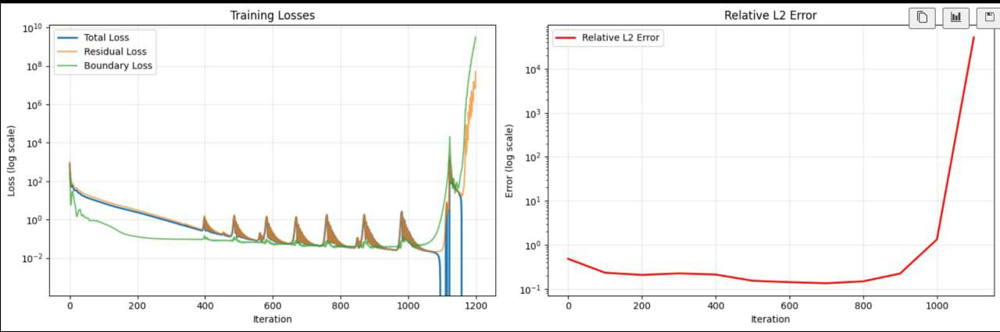